# Parte 3. Estabilidad del modelo con bootstrap

En esta parte se mide qué tan estables son los coeficientes del modelo final elegido en la parte 2. Se remuestrean
las filas de entrenamiento 10.000 veces, se reajusta el modelo en cada remuestra y se construyen IC bootstrap al
95 % (percentil y BCa) para los coeficientes y los odds ratios. Se comparan con los IC tradicionales de Wald y se
identifican los parámetros inestables.

Es la misma técnica de la S2 (`S2/01_bootstrap_ic.ipynb`), que validó con bootstrap los IC clásicos de la S1: B =
10.000, semilla 42 e IC percentil frente a BCa con aceleración por jackknife. La diferencia es que ahora el
estadístico no es una media sino el vector de coeficientes de un modelo multivariado.

Todo se lee de `config_modelo_final.json`, que escribe la parte 2: variables, estrategia de imputación, recorte y
ponderación. Así el bootstrap usa exactamente el modelo final.

## Configuración

In [1]:
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats
from sklearn.metrics import roc_auc_score

from utils_s3 import (
    SEED, B, ALPHA, OBJETIVO, NOMBRES, NUMERICAS, HALLAZGOS, COLORES, S3, TAB,
    cargar_datos, configurar_graficos, guardar_figura, guardar_tabla,
    particionar, imputar, preparar_modelo, ajustar_logit, predecir,
)

warnings.filterwarnings("ignore")
configurar_graficos()
df = cargar_datos()
train, test = particionar(df)
print(f"Observaciones: {len(df)} | entrenamiento: {len(train)} | prueba: {len(test)} | B = {B:,} | semilla = {SEED}")

Observaciones: 4240 | entrenamiento: 2968 | prueba: 1272 | B = 10,000 | semilla = 42


In [2]:
# los datos deben coincidir con la S1
assert len(df) == HALLAZGOS["S1"]["n"]
assert round(df[OBJETIVO].mean() * 100, 2) == HALLAZGOS["S1"]["tasa_chd_%"]
print("OK: los datos coinciden con la Sumativa 1")

OK: los datos coinciden con la Sumativa 1


## 3.0 Modelo final de la parte 2

Se carga la configuración, se imputa con la estrategia elegida (ajustada solo en entrenamiento), se preparan las
matrices con `preparar_modelo()` y se ajusta el modelo con `ajustar_logit()`. Antes de remuestrear se comprueba que
los coeficientes son los mismos de la parte 2.

In [3]:
config = json.loads((S3 / "config_modelo_final.json").read_text(encoding="utf-8"))
VARIABLES = config["variables"]
tr, te = imputar(train, test, config["estrategia_imputacion"])
X_tr, X_te, y_tr, y_te = preparar_modelo(tr, te, VARIABLES, recortar=config["recorte_outliers"])
modelo = ajustar_logit(X_tr, y_tr, ponderar=True)

referencia = pd.read_csv(TAB / "p2_modelo1_coeficientes.csv", index_col="variable")
assert np.allclose(modelo.params[VARIABLES].round(4), referencia.loc[VARIABLES, "coef"], atol=1e-4)
assert np.allclose(np.exp(modelo.conf_int().loc[VARIABLES]).round(4),
                   referencia.loc[VARIABLES, ["OR_IC95_inf", "OR_IC95_sup"]], atol=1e-4)
print("OK: coeficientes e IC iguales a los de la parte 2")
print(f"Variables: {', '.join(VARIABLES)} | imputación: {config['estrategia_imputacion']} | n = {len(y_tr)}")
modelo.params.round(4).to_frame("coef")

OK: coeficientes e IC iguales a los de la parte 2
Variables: age, male, sysBP, prevalentHyp, cigsPerDay, glucose | imputación: regresion | n = 2968


,coef
const,-0.5239
age,0.6534
male,0.3960
sysBP,0.2878
prevalentHyp,0.2455
cigsPerDay,0.2807
glucose,0.1699


## 3.1 Bootstrap de los coeficientes

Se remuestrean con reemplazo las 2.968 filas de entrenamiento. En cada remuestra se reajusta el mismo modelo:
mismas variables, misma escala (la estandarización de entrenamiento) y pesos de clase recalculados con la
remuestra, porque `pesos_clases()` los obtiene de `y`. En el bucle se usa `robusto=False`, que da los mismos
coeficientes y es más rápido. La imputación queda fija: el bootstrap mide la variabilidad del modelo, no la de la
imputación, que se revisa en la parte 4.

In [4]:
rng = np.random.default_rng(SEED)
n = len(y_tr)
X_arr, y_arr = X_tr.reset_index(drop=True), y_tr.reset_index(drop=True)
coefs = np.full((B, len(modelo.params)), np.nan)
no_convergen = 0
inicio = time.time()
for b in range(B):
    idx = rng.integers(0, n, n)
    try:
        m_b = ajustar_logit(X_arr.iloc[idx], y_arr.iloc[idx], ponderar=True, robusto=False)
        if m_b.converged:
            coefs[b] = m_b.params.values
        else:
            no_convergen += 1
    except Exception:
        no_convergen += 1
coefs = pd.DataFrame(coefs, columns=modelo.params.index).dropna()
print(f"Remuestras: {B:,} | válidas: {len(coefs):,} | no convergen: {no_convergen} | "
      f"tiempo: {time.time() - inicio:.0f} s")

Remuestras: 10,000 | válidas: 10,000 | no convergen: 0 | tiempo: 51 s


Para el IC BCa la aceleración se estima con jackknife: se reajusta el modelo quitando una fila a la vez (2.968
ajustes), igual que en la S2.

In [5]:
jack = np.empty((n, len(modelo.params)))
for i in range(n):
    mantener = np.arange(n) != i
    jack[i] = ajustar_logit(X_arr[mantener], y_arr[mantener], ponderar=True, robusto=False).params.values
jack = pd.DataFrame(jack, columns=modelo.params.index)


def intervalo_bca(distribucion, estimacion, jackknife, alpha=ALPHA):
    """IC BCa de Efron a partir de una distribución y valores jackknife (igual que en la S2)."""
    proporcion = (np.sum(distribucion < estimacion) + .5 * np.sum(distribucion == estimacion)) / len(distribucion)
    proporcion = np.clip(proporcion, 1 / (2 * len(distribucion)), 1 - 1 / (2 * len(distribucion)))
    z0 = stats.norm.ppf(proporcion)
    diferencias = jackknife.mean() - jackknife
    aceleracion = np.sum(diferencias ** 3) / (6 * np.sum(diferencias ** 2) ** 1.5)
    z = stats.norm.ppf([alpha / 2, 1 - alpha / 2])
    probabilidades = stats.norm.cdf(z0 + (z0 + z) / (1 - aceleracion * (z0 + z)))
    return np.quantile(distribucion, probabilidades)

## 3.2 Distribuciones bootstrap

Un panel por coeficiente con la estimación, el IC de Wald (EE robustos, como en la parte 2) y los IC percentil y
BCa. La línea gris marca el cero: si la distribución lo cruza, el signo del efecto no es seguro.

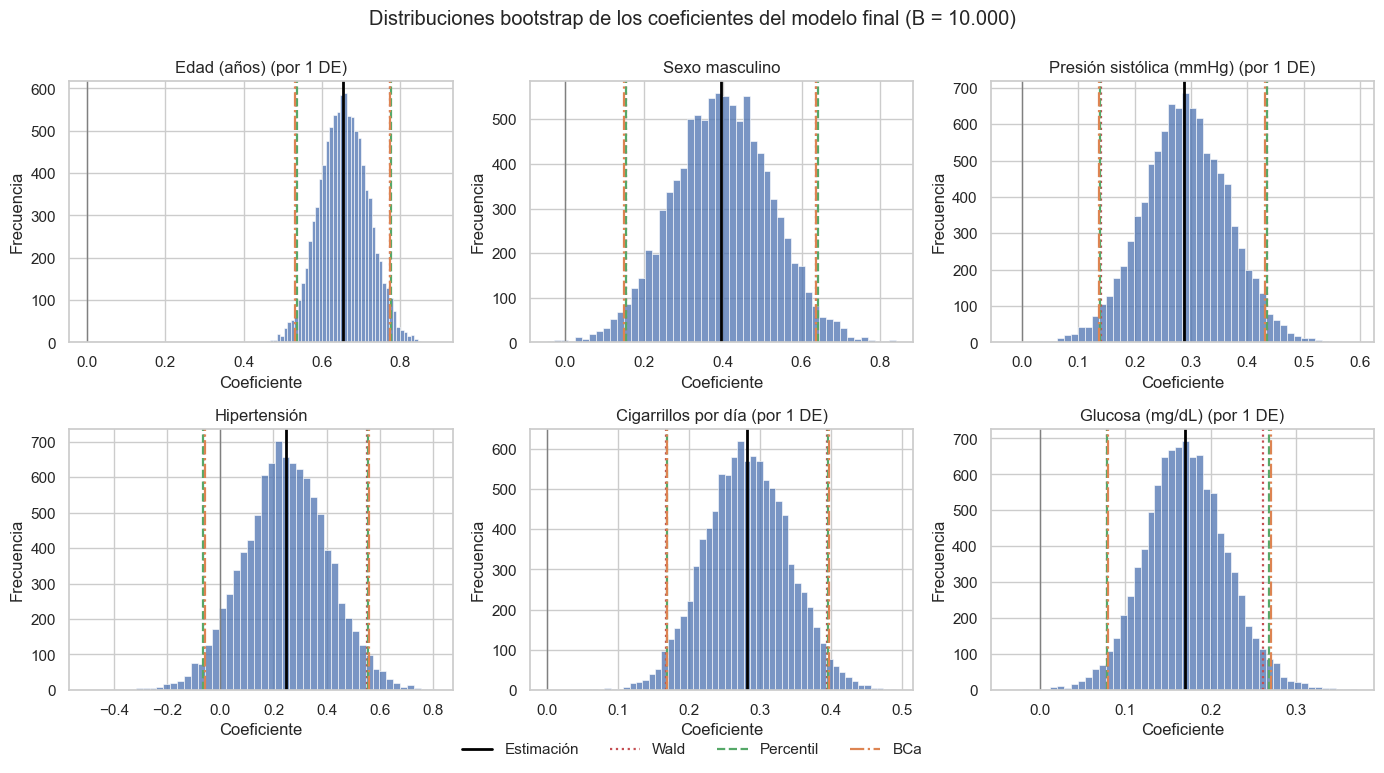

In [6]:
wald = modelo.conf_int()
ic_perc = coefs.quantile([ALPHA / 2, 1 - ALPHA / 2]).T
ic_bca = pd.DataFrame({v: intervalo_bca(coefs[v].values, modelo.params[v], jack[v].values) for v in coefs},
                      index=[0, 1]).T

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, v in zip(axes.flat, VARIABLES):
    sns.histplot(coefs[v], bins=50, color=COLORES["principal"], alpha=.75, ax=ax)
    ax.axvline(modelo.params[v], color="black", lw=2, label="Estimación")
    for ic, color, estilo, etiqueta in [(wald, COLORES["riesgo"], ":", "Wald"),
                                         (ic_perc, COLORES["ic"], "--", "Percentil"),
                                         (ic_bca, "#DD8452", "-.", "BCa")]:
        ax.axvline(ic.loc[v, ic.columns[0]], color=color, lw=1.6, ls=estilo, label=etiqueta)
        ax.axvline(ic.loc[v, ic.columns[1]], color=color, lw=1.6, ls=estilo)
    ax.axvline(0, color="0.5", lw=1)
    ax.set(title=NOMBRES[v] + (" (por 1 DE)" if v in NUMERICAS else ""), xlabel="Coeficiente", ylabel="Frecuencia")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.02))
plt.suptitle(f"Distribuciones bootstrap de los coeficientes del modelo final (B = {len(coefs):,})".replace(",", "."), y=.995)
plt.tight_layout(rect=[0, .04, 1, .97])
guardar_figura("p3_fig1_distribuciones_bootstrap")

## 3.3 IC bootstrap y tradicionales

La tabla reúne, para cada coeficiente, la estimación, el odds ratio y sus IC al 95 % de Wald, percentil y BCa. Los
IC de los odds ratios son la exponencial de los extremos. En las variables continuas el odds ratio corresponde a un
aumento de 1 DE.

Los criterios se fijaron antes de mirar los resultados y se aplican tal cual. Un parámetro es **inestable** si
cumple al menos uno:

- (a) su IC bootstrap (percentil o BCa) incluye el 0;
- (b) cambia de signo en 2,5 % o más de las remuestras (equivale a que una cola del IC 95 % cruce el 0);
- (c) la razón de anchos IC percentil / IC Wald queda fuera de [0,8; 1,25].

Además se marca si el bootstrap y Wald **discrepan** (uno incluye el 0 y el otro no). "No significativo" e
"inestable" no son lo mismo: el primero se refiere al p de Wald; el segundo, a que la conclusión (el signo o el
ancho del IC) cambia con la muestra. La tabla indica qué criterio se cumple en cada caso.

Los criterios (a) y (b) son casi redundantes: un 2,5 % de remuestras con signo opuesto es justo lo que hace que una
cola del IC percentil 95 % toque el 0. Por eso un coeficiente no significativo tiende a cumplir los dos a la vez. Se
mantiene (b) porque cuantifica qué tan seguido se invierte el signo, y eso es lo que permite hablar de una
dirección incierta y no solo de falta de significación.

In [7]:
signo = np.sign(modelo.params[VARIABLES])
tabla = pd.DataFrame({
    "coef": modelo.params[VARIABLES],
    "EE_robusto": modelo.bse[VARIABLES],
    "EE_bootstrap": coefs[VARIABLES].std(),
    "sesgo_bootstrap": coefs[VARIABLES].mean() - modelo.params[VARIABLES],
    "p_Wald": modelo.pvalues[VARIABLES],
    "Wald_inf": wald.loc[VARIABLES, 0], "Wald_sup": wald.loc[VARIABLES, 1],
    "perc_inf": ic_perc.loc[VARIABLES].iloc[:, 0], "perc_sup": ic_perc.loc[VARIABLES].iloc[:, 1],
    "BCa_inf": ic_bca.loc[VARIABLES, 0], "BCa_sup": ic_bca.loc[VARIABLES, 1],
})
tabla.insert(5, "OR", np.exp(tabla["coef"]))
for metodo in ["Wald", "perc", "BCa"]:
    tabla[f"OR_{metodo}_inf"] = np.exp(tabla[f"{metodo}_inf"])
    tabla[f"OR_{metodo}_sup"] = np.exp(tabla[f"{metodo}_sup"])
tabla["%_signo_opuesto"] = [(np.sign(coefs[v]) != signo[v]).mean() * 100 for v in VARIABLES]
tabla["razon_anchos"] = (tabla["perc_sup"] - tabla["perc_inf"]) / (tabla["Wald_sup"] - tabla["Wald_inf"])

incluye_0 = lambda metodo: (tabla[f"{metodo}_inf"] < 0) & (tabla[f"{metodo}_sup"] > 0)
criterios = pd.DataFrame({
    "a": incluye_0("perc") | incluye_0("BCa"),
    "b": tabla["%_signo_opuesto"] >= 2.5,
    "c": ~tabla["razon_anchos"].between(0.8, 1.25),
})
tabla["discrepa_Wald_boot"] = incluye_0("Wald") != (incluye_0("perc") | incluye_0("BCa"))
tabla["criterios"] = criterios.apply(lambda f: ", ".join(f.index[f]) or "ninguno", axis=1)
tabla["clasificacion"] = np.where(~criterios.any(axis=1), "estable",
                                  np.where(tabla["p_Wald"] >= ALPHA, "inestable (no significativo)", "inestable"))
tabla.insert(0, "escala_OR", ["1 DE" if v in NUMERICAS else "sí vs no" for v in VARIABLES])
tabla.index = [NOMBRES[v] for v in VARIABLES]
tabla.index.name = "variable"
guardar_tabla(tabla.round(4), "p3_estabilidad_bootstrap")

,escala_OR,coef,EE_robusto,EE_bootstrap,sesgo_bootstrap,p_Wald,OR,Wald_inf,Wald_sup,perc_inf,...,OR_Wald_sup,OR_perc_inf,OR_perc_sup,OR_BCa_inf,OR_BCa_sup,%_signo_opuesto,razon_anchos,discrepa_Wald_boot,criterios,clasificacion
variable,,,,,,,,,,,,,,,,,,,,,
Edad (años),1 DE,0.6534,0.0610,0.0617,0.0027,0.0000,1.9220,0.5338,0.7729,0.5367,...,2.1661,1.7103,2.1759,1.7015,2.1660,0.0000,1.0070,False,ninguno,estable
Sexo masculino,sí vs no,0.3960,0.1223,0.1249,0.0022,0.0012,1.4858,0.1564,0.6356,0.1540,...,1.8881,1.1665,1.9004,1.1609,1.8904,0.0800,1.0185,False,ninguno,estable
Presión sistólica (mmHg),1 DE,0.2878,0.0749,0.0759,0.0014,0.0001,1.3335,0.1410,0.4346,0.1383,...,1.5444,1.1483,1.5461,1.1455,1.5406,0.0100,1.0132,False,ninguno,estable
Hipertensión,sí vs no,0.2455,0.1572,0.1582,0.0004,0.1184,1.2782,-0.0626,0.5536,-0.0639,...,1.7395,0.9381,1.7447,0.9422,1.7495,6.0400,1.0069,False,"a, b",inestable (no significativo)
Cigarrillos por día,1 DE,0.2807,0.0579,0.0587,0.0001,0.0000,1.3240,0.1671,0.3942,0.1679,...,1.4833,1.1828,1.4848,1.1835,1.4863,0.0000,1.0013,False,ninguno,estable
Glucosa (mg/dL),1 DE,0.1699,0.0468,0.0483,0.0011,0.0003,1.1851,0.0781,0.2617,0.0785,...,1.2991,1.0817,1.3079,1.0833,1.3109,0.0500,1.0345,False,ninguno,estable


In [8]:
# vista compacta para el informe y la presentación
compacta = pd.DataFrame({
    "OR": tabla["OR"].round(2),
    "IC Wald": [f"[{a:.2f}; {b:.2f}]" for a, b in zip(tabla["OR_Wald_inf"], tabla["OR_Wald_sup"])],
    "IC percentil": [f"[{a:.2f}; {b:.2f}]" for a, b in zip(tabla["OR_perc_inf"], tabla["OR_perc_sup"])],
    "IC BCa": [f"[{a:.2f}; {b:.2f}]" for a, b in zip(tabla["OR_BCa_inf"], tabla["OR_BCa_sup"])],
    "% signo opuesto": tabla["%_signo_opuesto"].round(2),
    "razón de anchos": tabla["razon_anchos"].round(2),
    "criterios": tabla["criterios"],
    "clasificación": tabla["clasificacion"],
})
compacta

,OR,IC Wald,IC percentil,IC BCa,% signo opuesto,razón de anchos,criterios,clasificación
variable,,,,,,,,
Edad (años),1.9200,[1.71; 2.17],[1.71; 2.18],[1.70; 2.17],0.0000,1.0100,ninguno,estable
Sexo masculino,1.4900,[1.17; 1.89],[1.17; 1.90],[1.16; 1.89],0.0800,1.0200,ninguno,estable
Presión sistólica (mmHg),1.3300,[1.15; 1.54],[1.15; 1.55],[1.15; 1.54],0.0100,1.0100,ninguno,estable
Hipertensión,1.2800,[0.94; 1.74],[0.94; 1.74],[0.94; 1.75],6.0400,1.0100,"a, b",inestable (no significativo)
Cigarrillos por día,1.3200,[1.18; 1.48],[1.18; 1.48],[1.18; 1.49],0.0000,1.0000,ninguno,estable
Glucosa (mg/dL),1.1900,[1.08; 1.30],[1.08; 1.31],[1.08; 1.31],0.0500,1.0300,ninguno,estable


Los odds ratios por 1 DE son difíciles de leer en consulta. Con las mismas remuestras se pasan a unidades clínicas
(OR por Δ unidades = exp(β / DE × Δ), con la DE de entrenamiento), igual que en la tabla `p2_modelo1_or_clinicos`.

In [9]:
de = tr[["age", "sysBP", "cigsPerDay", "glucose"]].std(ddof=0)
unidades = {"age": "10 años", "sysBP": "10 mmHg", "cigsPerDay": "10 cigarrillos", "glucose": "10 mg/dL"}
clinicos = pd.DataFrame({
    "aumento": list(unidades.values()),
    "OR": [np.exp(modelo.params[v] / de[v] * 10) for v in unidades],
    "Wald_inf": [np.exp(wald.loc[v, 0] / de[v] * 10) for v in unidades],
    "Wald_sup": [np.exp(wald.loc[v, 1] / de[v] * 10) for v in unidades],
    "perc_inf": [np.exp(coefs[v].quantile(ALPHA / 2) / de[v] * 10) for v in unidades],
    "perc_sup": [np.exp(coefs[v].quantile(1 - ALPHA / 2) / de[v] * 10) for v in unidades],
}, index=[NOMBRES[v] for v in unidades])
guardar_tabla(clinicos.round(3), "p3_or_clinicos_bootstrap")

,aumento,OR,Wald_inf,Wald_sup,perc_inf,perc_sup
Edad (años),10 años,2.1360,1.8590,2.4540,1.8650,2.4670
Presión sistólica (mmHg),10 mmHg,1.1410,1.0670,1.2200,1.0650,1.2210
Cigarrillos por día,10 cigarrillos,1.2660,1.1510,1.3930,1.1510,1.3940
Glucosa (mg/dL),10 mg/dL,1.0740,1.0340,1.1170,1.0340,1.1200


## 3.4 Comparación gráfica: Wald frente a bootstrap

El forest plot muestra los odds ratios con los tres IC en escala logarítmica. La línea vertical en 1 indica
ausencia de efecto.

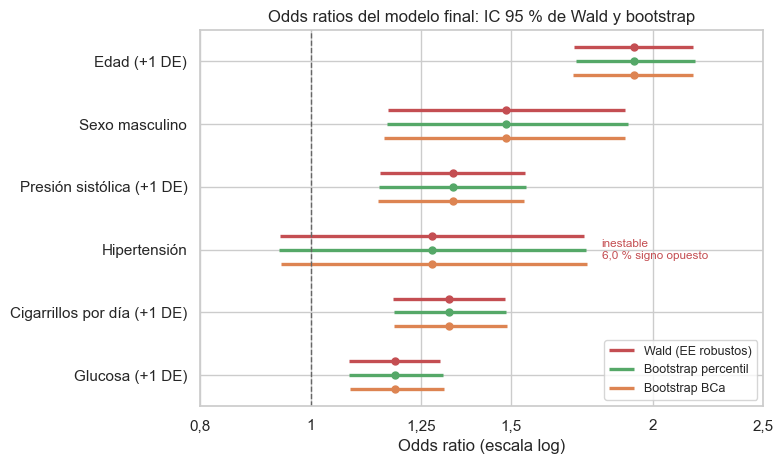

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.8))
posiciones = np.arange(len(VARIABLES))[::-1]
for desplazamiento, (inf, sup, color, etiqueta) in zip([0.22, 0, -0.22], [
        ("OR_Wald_inf", "OR_Wald_sup", COLORES["riesgo"], "Wald (EE robustos)"),
        ("OR_perc_inf", "OR_perc_sup", COLORES["ic"], "Bootstrap percentil"),
        ("OR_BCa_inf", "OR_BCa_sup", "#DD8452", "Bootstrap BCa")]):
    y = posiciones + desplazamiento
    ax.hlines(y, tabla[inf], tabla[sup], color=color, lw=2.4, label=etiqueta)
    ax.plot(tabla["OR"], y, "o", color=color, ms=5)
ax.axvline(1, color="0.4", lw=1, ls="--")
ax.set_xscale("log")
ticks = [0.8, 1, 1.25, 1.5, 2, 2.5]
ax.set_xticks(ticks, [str(t).replace(".", ",") for t in ticks])
ETIQUETAS = {"age": "Edad (+1 DE)", "male": "Sexo masculino", "sysBP": "Presión sistólica (+1 DE)",
             "prevalentHyp": "Hipertensión", "cigsPerDay": "Cigarrillos por día (+1 DE)", "glucose": "Glucosa (+1 DE)"}
ax.set_yticks(posiciones, [ETIQUETAS.get(v, NOMBRES[v]) for v in VARIABLES])
for p, (i, fila) in zip(posiciones, tabla.iterrows()):
    if fila["clasificacion"] != "estable":
        texto = f"inestable\n{fila['%_signo_opuesto']:.1f} % signo opuesto".replace(".", ",")
        ax.text(fila["OR_BCa_sup"] * 1.03, p, texto, va="center", fontsize=8.5, color=COLORES["riesgo"])
ax.set(xlabel="Odds ratio (escala log)", title="Odds ratios del modelo final: IC 95 % de Wald y bootstrap")
ax.legend(loc="lower right", fontsize=9)
guardar_figura("p3_fig2_forest_or")

## 3.5 Extra: incertidumbre del AUC y del recall en prueba

El modelo final se mantiene fijo y se remuestrean las 1.272 filas de prueba 10.000 veces. Así se obtienen IC para
el AUC (0,708) y el recall (0,632), y se puede juzgar si las diferencias de AUC entre los tres modelos de la parte 2
(0,700 a 0,708) son relevantes.

In [11]:
rng_auc = np.random.default_rng(SEED)
p_te = np.asarray(predecir(modelo, X_te))
y_te_arr = y_te.to_numpy()
pred_te = (p_te >= config["umbral"]).astype(int)
auc_obs = roc_auc_score(y_te_arr, p_te)
recall_obs = pred_te[y_te_arr == 1].mean()
aucs, recalls = np.empty(B), np.empty(B)
for b in range(B):
    idx = rng_auc.integers(0, len(y_te_arr), len(y_te_arr))
    aucs[b] = roc_auc_score(y_te_arr[idx], p_te[idx])
    recalls[b] = pred_te[idx][y_te_arr[idx] == 1].mean()
auc_tabla = pd.DataFrame({
    "estimacion": [auc_obs, recall_obs], "EE_bootstrap": [aucs.std(), recalls.std()],
    "perc_inf": [np.quantile(aucs, ALPHA / 2), np.quantile(recalls, ALPHA / 2)],
    "perc_sup": [np.quantile(aucs, 1 - ALPHA / 2), np.quantile(recalls, 1 - ALPHA / 2)],
}, index=["AUC prueba", "recall prueba"])
guardar_tabla(auc_tabla.round(3), "p3_metricas_bootstrap")

,estimacion,EE_bootstrap,perc_inf,perc_sup
AUC prueba,0.7080,0.0200,0.6690,0.7450
recall prueba,0.6320,0.0350,0.5620,0.7010


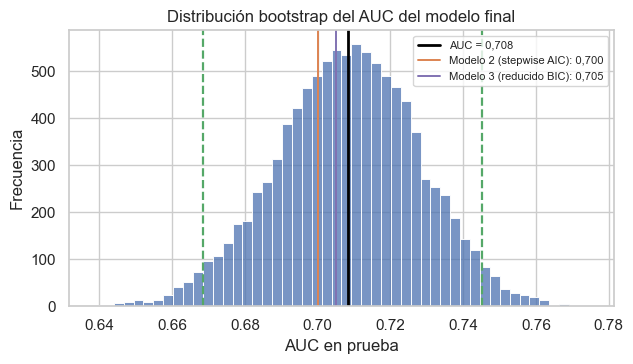

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
sns.histplot(aucs, bins=50, color=COLORES["principal"], alpha=.75, ax=ax)
ax.axvline(auc_obs, color="black", lw=2, label=f"AUC = {auc_obs:.3f}".replace(".", ","))
for q in auc_tabla.loc["AUC prueba", ["perc_inf", "perc_sup"]]:
    ax.axvline(q, color=COLORES["ic"], lw=1.6, ls="--")
resumen_p2 = pd.read_csv(TAB / "p2_resumen_modelos.csv", index_col="modelo")["AUC prueba"]
for nombre, color in zip(["Modelo 2 (stepwise AIC)", "Modelo 3 (reducido BIC)"], ["#DD8452", "#8172B2"]):
    ax.axvline(resumen_p2[nombre], color=color, lw=1.4, label=f"{nombre}: {resumen_p2[nombre]:.3f}".replace(".", ","))
ax.set(xlabel="AUC en prueba", ylabel="Frecuencia", title="Distribución bootstrap del AUC del modelo final")
ax.legend(fontsize=8)
guardar_figura("p3_fig3_auc_bootstrap")

## 3.6 Resultados e implicancias

**Convergencia.** Las 10.000 remuestras convergieron; ninguna se descartó. El bucle tarda alrededor de un minuto.

**Cinco coeficientes estables.** Edad, sexo masculino, presión sistólica, cigarrillos por día y glucosa no
cumplen ningún criterio de inestabilidad. Sus IC bootstrap excluyen el 0, cambian de signo en a lo más 0,08 % de
las remuestras y tienen el mismo ancho que los de Wald (razón entre 1,00 y 1,03). El sesgo bootstrap es menor que
0,003 en todos.

| Variable | OR | IC Wald | IC percentil | IC BCa | % signo opuesto |
| --- | --- | --- | --- | --- | --- |
| Edad (+1 DE) | 1,92 | [1,71; 2,17] | [1,71; 2,18] | [1,70; 2,17] | 0,00 |
| Sexo masculino | 1,49 | [1,17; 1,89] | [1,17; 1,90] | [1,16; 1,89] | 0,08 |
| Presión sistólica (+1 DE) | 1,33 | [1,15; 1,54] | [1,15; 1,55] | [1,15; 1,54] | 0,01 |
| Hipertensión | 1,28 | [0,94; 1,74] | [0,94; 1,74] | [0,94; 1,75] | 6,04 |
| Cigarrillos por día (+1 DE) | 1,32 | [1,18; 1,48] | [1,18; 1,48] | [1,18; 1,49] | 0,00 |
| Glucosa (+1 DE) | 1,19 | [1,08; 1,30] | [1,08; 1,31] | [1,08; 1,31] | 0,05 |

En unidades clínicas, cada 10 años de edad multiplican la odds de CHD por 2,14 (IC bootstrap [1,87; 2,47]), cada
10 cigarrillos diarios por 1,27 ([1,15; 1,39]), cada 10 mmHg de sistólica por 1,14 ([1,07; 1,22]) y cada 10 mg/dL
de glucosa por 1,07 ([1,03; 1,12]).

**Un parámetro inestable, de dirección incierta: hipertensión.** Cumple los criterios (a) y (b), que como se
dijo van juntos: sus IC percentil y BCa incluyen el 0
(OR de 0,94 a 1,75) y el coeficiente tiene signo opuesto en 6,0 % de las remuestras. Ya era no significativa con
Wald (p = 0,118), así que el bootstrap no contradice a Wald: lo que agrega es que **la dirección** del efecto no
es segura, no solo su significación. Su efecto bivariado de la S1 (24,7 % de CHD con hipertensión frente a 10,9 %
sin ella) queda absorbido por la presión sistólica y la edad cuando se ajusta por ellas. Ninguna variable
discrepa entre Wald y bootstrap.

**Por qué Wald y bootstrap coinciden.** Los IC de Wald de la parte 2 ya usan errores estándar robustos (HC0,
sandwich), que son la aproximación asintótica de la varianza que estima el bootstrap de filas. Con 2.968
observaciones y 6 predictores, además, la distribución de cada coeficiente es casi normal (histogramas de la
sección 3.2), y los EE bootstrap difieren de los robustos en menos de 0,003. Que coincidan no significa que el
bootstrap no aporte: confirma sin suponer normalidad que los IC de la parte 2 son confiables, mide el sesgo (casi
nulo) y cuantifica cuántas veces cambia el signo, que es lo que permite separar "no significativo" de
"inestable". La distribución de la glucosa es levemente asimétrica: su IC bootstrap llega a un OR de 1,31 frente a
1,30 con Wald. La diferencia es mínima y no cambia ninguna conclusión.

**AUC y recall en prueba.** El AUC de 0,708 tiene IC bootstrap [0,669; 0,745] y el recall de 0,632, [0,562;
0,701]. Los AUC de los modelos 2 (0,700) y 3 (0,705) caen dentro de ese intervalo: la diferencia de AUC entre los
tres modelos no basta para elegir. La elección del modelo 1 se apoya en la parsimonia, el respaldo de la S1 y la
S2 y el recall (parte 2).

**Conexión con la S1 y la S2.**

- Edad y presión sistólica, las dos mayores diferencias de la S1 (g = 0,64 y 0,62) y validadas por bootstrap en la
  S2, son los efectos más estables.
- Los cigarrillos por día son estables una vez ajustados por edad, como anticipó la S2 (Mantel-Haenszel p < 0,001)
  pese a la asociación bivariada débil de la S1 (g = 0,16).
- La glucosa es estable en el modelo aunque en la S2 su diferencia entre grupos bajaba 90 % sin atípicos. En el
  modelo multivariado su efecto es pequeño (1,07 por 10 mg/dL) pero de signo seguro (0,05 % de signo opuesto).
- La hipertensión es la única inestable, en línea con la recomendación de la S2 de evaluarla ajustada por edad.

**Implicancias para la decisión.**

- Se pueden comunicar con confianza los efectos de edad, sexo, presión sistólica, tabaquismo y glucosa: su
  dirección y su magnitud no dependen de la muestra.
- La hipertensión debe comunicarse con cautela: no se puede afirmar un efecto independiente de la sistólica. El
  mensaje práctico es controlar la presión sistólica, cuyo efecto sí es estable. Se mantiene en el modelo por su
  relevancia clínica y porque no daña al resto (VIF bajo 2,2); el modelo 3 (BIC), que la excluye, es la
  alternativa más simple con un AUC casi igual (0,705).
- El bootstrap mantiene fija la imputación por regresión: mide la variabilidad del modelo, no la de la
  imputación, que se revisa en la parte 4.